In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df = pd.read_csv("C:\\Users\\NAGARAJ P\\Desktop\\X_G\\creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.info()
df.describe()
df.dtypes
df.columns.tolist

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

<bound method IndexOpsMixin.tolist of Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')>

In [6]:
# Checking the Class Imbalance

print(df["Class"].value_counts())

print("\nPercentage distribution:")
print(df["Class"].value_counts(normalize=True) * 100)

print("\nFraud cases:", (df["Class"] == 1).sum())
print("Legitimate cases:", (df["Class"] == 0).sum())

Class
0    284315
1       492
Name: count, dtype: int64

Percentage distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Fraud cases: 492
Legitimate cases: 284315


In [7]:
from sklearn.model_selection import train_test_split

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (227845, 30)
Testing data: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [8]:

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

# Calculate class weight
scale_pos_weight = negative / positive

print("Legitimate cases:", negative)
print("Fraud cases:", positive)
print("Scale positive weight:", scale_pos_weight)

Legitimate cases: 227451
Fraud cases: 394
Scale positive weight: 577.2868020304569


In [10]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Average Precision (PR-AUC):",
      average_precision_score(y_test, y_prob))

Confusion Matrix:
[[56815    49]
 [   16    82]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.63      0.84      0.72        98

    accuracy                           1.00     56962
   macro avg       0.81      0.92      0.86     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9861944144568351
Average Precision (PR-AUC): 0.8534185266857303


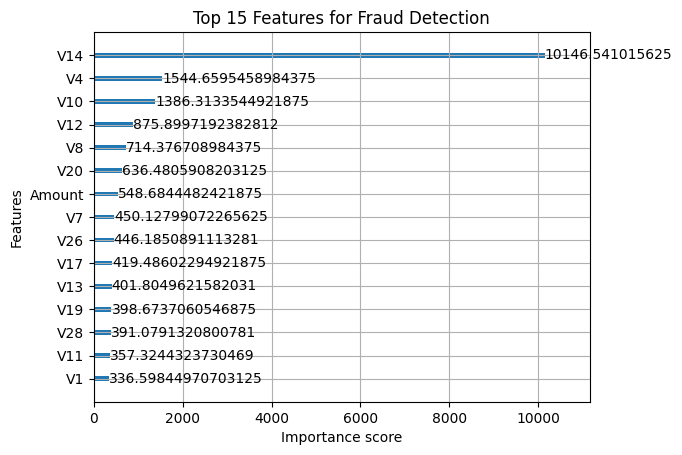

In [12]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

plot_importance(
    model,
    max_num_features=15,
    importance_type="gain"
)

plt.title("Top 15 Features for Fraud Detection")
plt.show()

In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_test, y_threshold), 3
    ))
    print("Recall:", round(
        recall_score(y_test, y_threshold), 3
    ))
    print("F1-score:", round(
        f1_score(y_test, y_threshold), 3
    ))


Threshold: 0.3
Precision: 0.486
Recall: 0.878
F1-score: 0.625

Threshold: 0.4
Precision: 0.557
Recall: 0.847
F1-score: 0.672

Threshold: 0.5
Precision: 0.626
Recall: 0.837
F1-score: 0.716

Threshold: 0.6
Precision: 0.695
Recall: 0.837
F1-score: 0.759

Threshold: 0.7
Precision: 0.771
Recall: 0.827
F1-score: 0.798


In [14]:
from sklearn.metrics import confusion_matrix

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_threshold
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print("Fraud detected:", tp)
    print("Fraud missed:", fn)
    print("False alarms:", fp)


Threshold: 0.3
Fraud detected: 86
Fraud missed: 12
False alarms: 91

Threshold: 0.4
Fraud detected: 83
Fraud missed: 15
False alarms: 66

Threshold: 0.5
Fraud detected: 82
Fraud missed: 16
False alarms: 49

Threshold: 0.6
Fraud detected: 82
Fraud missed: 16
False alarms: 36

Threshold: 0.7
Fraud detected: 81
Fraud missed: 17
False alarms: 24


In [15]:
# Retraining the model.....
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)

Training: (182276, 30)
Validation: (45569, 30)


In [16]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier

negative = (y_train_new == 0).sum()
positive = (y_train_new == 1).sum()
weight = negative / positive

params_grid = {
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200],
    "min_child_weight": [1, 5]
}

best_ap = -1
best_params = None
best_model = None

for params in ParameterGrid(params_grid):
    model_try = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=weight,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        **params
    )

    model_try.fit(X_train_new, y_train_new)

    val_prob = model_try.predict_proba(X_val)[:, 1]
    ap = average_precision_score(y_val, val_prob)

    print(params, "Validation Average Precision:", round(ap, 4))

    if ap > best_ap:
        best_ap = ap
        best_params = params
        best_model = model_try

print("\nBest parameters:", best_params)
print("Best validation Average Precision:", round(best_ap, 4))

{'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 200} Validation Average Precision: 0.7623
{'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200} Validation Average Precision: 0.7552
{'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 200} Validation Average Precision: 0.7939
{'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 5, 'n_estimators': 200} Validation Average Precision: 0.8087
{'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 200} Validation Average Precision: 0.7964
{'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200} Validation Average Precision: 0.7888
{'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 200} Validation Average Precision: 0.8284
{'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 5, 'n_estimators': 200} Validation Average Precision: 0.8275

Best parameters: {'learning_rate': 

In [17]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Calculate class weight using all training data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()
weight = negative / positive

# Create the tuned model
tuned_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=weight,
    random_state=42,
    n_jobs=-1
)

# Train on all training data
tuned_model.fit(X_train, y_train)

# Evaluate on the untouched test set
tuned_prob = tuned_model.predict_proba(X_test)[:, 1]
tuned_pred = (tuned_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, tuned_pred))

print("\nClassification Report:")
print(classification_report(y_test, tuned_pred, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, tuned_prob))
print("Average Precision:", average_precision_score(y_test, tuned_prob))

Confusion Matrix:
[[56849    15]
 [   16    82]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.979304362431523
Average Precision: 0.8664979157653611


In [18]:
baseline_val_prob = model.predict_proba(X_val)[:, 1]

tuned_val_prob = tuned_model.predict_proba(X_val)[:, 1]

In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    y_val_pred = (tuned_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1-Score": f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)
threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.3,0.940476,1.0,0.969325
1,0.4,0.951807,1.0,0.975309
2,0.5,0.963415,1.0,0.981366
3,0.6,0.963415,1.0,0.981366
4,0.7,0.963415,1.0,0.981366


In [20]:
best_row = threshold_results.loc[
    threshold_results["F1-Score"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Selected threshold:", best_threshold)
print(best_row)

Selected threshold: 0.5
Threshold    0.500000
Precision    0.963415
Recall       1.000000
F1-Score     0.981366
Name: 2, dtype: float64


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold = 0.5

baseline_pred = (baseline_val_prob >= threshold).astype(int)
tuned_pred = (tuned_val_prob >= threshold).astype(int)

comparison = pd.DataFrame({
    "Model": ["Baseline XGBoost", "Tuned XGBoost"],
    "Precision": [
        precision_score(y_val, baseline_pred, zero_division=0),
        precision_score(y_val, tuned_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_val, baseline_pred, zero_division=0),
        recall_score(y_val, tuned_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_val, baseline_pred, zero_division=0),
        f1_score(y_val, tuned_pred, zero_division=0)
    ]
})

comparison

,Model,Precision,Recall,F1-Score
0,Baseline XGBoost,0.790000,1.0,0.882682
1,Tuned XGBoost,0.963415,1.0,0.981366


In [22]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

y_test_prob = tuned_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

print("Average Precision:", average_precision_score(y_test, y_test_prob))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

Confusion Matrix:
[[56849    15]
 [   16    82]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Average Precision: 0.8664979157653611
ROC-AUC: 0.979304362431523


In [23]:
import joblib

joblib.dump(tuned_model, "xgboost_fraud_model.pkl")

print("Model saved successfully!")

Model saved successfully!
